In [2]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col

spark = SparkSession.builder \
    .appName("Pertemuan14-KMeansClustering") \
    .master("local[*]") \
    .getOrCreate()
spark.sparkContext.setLogLevel("ERROR")
spark.conf.set("spark.sql.shuffle.partitions", "4")

print("SparkSession siap. Versi Spark:", spark.version)

SparkSession siap. Versi Spark: 3.5.9


In [3]:
import numpy as np
import pandas as pd

np.random.seed(140)
n_menu = 60

# Tiga pola menu: (1) murah & sangat populer, (2) mahal & jarang dipesan, (3) sedang & cukup populer
pola_1 = pd.DataFrame({
    "harga": np.random.normal(18000, 2000, 20),
    "rata_rata_pesanan_harian": np.random.normal(45, 8, 20),
})
pola_2 = pd.DataFrame({
    "harga": np.random.normal(45000, 5000, 20),
    "rata_rata_pesanan_harian": np.random.normal(8, 3, 20),
})
pola_3 = pd.DataFrame({
    "harga": np.random.normal(28000, 3000, 20),
    "rata_rata_pesanan_harian": np.random.normal(22, 5, 20),
})

data_tugas14 = pd.concat([pola_1, pola_2, pola_3], ignore_index=True)
data_tugas14["harga"] = data_tugas14["harga"].clip(lower=10000).round(-2)
data_tugas14["rata_rata_pesanan_harian"] = data_tugas14["rata_rata_pesanan_harian"].clip(lower=1).round(1)
data_tugas14["menu_id"] = [f"MENU-{i:03d}" for i in range(len(data_tugas14))]
data_tugas14 = data_tugas14.sample(frac=1, random_state=1).reset_index(drop=True)  # acak urutan barisnya

data_tugas14.to_csv("tugas14_menu.csv", index=False)
print(f"Dataset berhasil dibuat: {len(data_tugas14)} menu")
print(data_tugas14.head())

Dataset berhasil dibuat: 60 menu
     harga  rata_rata_pesanan_harian   menu_id
0  40000.0                       9.4  MENU-039
1  31000.0                      15.3  MENU-041
2  18400.0                      62.9  MENU-002
3  30500.0                      24.8  MENU-048
4  26500.0                      25.9  MENU-050


In [6]:
from pyspark.ml.feature import VectorAssembler, StandardScaler

df_menu = spark.read.csv("tugas14_menu.csv", header=True, inferSchema=True)

assembler_menu = VectorAssembler(
    inputCols=["harga", "rata_rata_pesanan_harian"],
    outputCol="features_mentah"
)
df_menu_asm = assembler_menu.transform(df_menu)

scaler_menu = StandardScaler(inputCol="features_mentah", outputCol="features", withStd=True, withMean=True)
scaler_menu_model = scaler_menu.fit(df_menu_asm)
df_menu_scaled = scaler_menu_model.transform(df_menu_asm)

df_menu_scaled.select("menu_id", "harga", "rata_rata_pesanan_harian", "features").show(5, truncate=False)

+--------+-------+------------------------+--------------------------------------------+
|menu_id |harga  |rata_rata_pesanan_harian|features                                    |
+--------+-------+------------------------+--------------------------------------------+
|MENU-039|40000.0|9.4                     |[0.8697214695613823,-0.9787156001973806]    |
|MENU-041|31000.0|15.3                    |[0.08736332602790525,-0.6388437908292494]   |
|MENU-002|18400.0|62.9                    |[-1.0079380749189626,2.10317284068313]      |
|MENU-048|30500.0|24.8                    |[0.043898984720489864,-0.09159257235514]    |
|MENU-050|26500.0|25.9                    |[-0.30381574573883324,-0.028226641794980082]|
+--------+-------+------------------------+--------------------------------------------+
only showing top 5 rows



In [7]:
from pyspark.ml.clustering import KMeans
import matplotlib.pyplot as plt

hasil_wssse_menu = []
for k in range(2, 7):
    km_coba = KMeans(featuresCol="features", k=k, seed=42)
    model_coba = km_coba.fit(df_menu_scaled)
    wssse = model_coba.summary.trainingCost
    hasil_wssse_menu.append((k, wssse))
    print(f"k={k}  ->  WSSSE = {wssse:.2f}")

k_vals = [item[0] for item in hasil_wssse_menu]
wssse_vals = [item[1] for item in hasil_wssse_menu]

plt.figure(figsize=(8, 5))
plt.plot(k_vals, wssse_vals, marker="o", color="#1F3864")
plt.title("Elbow Method: Segmentasi Menu Kopi Nusantara")
plt.xlabel("Jumlah Klaster (k)")
plt.ylabel("WSSSE")
plt.xticks(k_vals)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

k=2  ->  WSSSE = 38.56
k=3  ->  WSSSE = 12.68
k=4  ->  WSSSE = 9.63
k=5  ->  WSSSE = 7.48
k=6  ->  WSSSE = 7.01


<Figure size 800x500 with 1 Axes>

In [8]:
from pyspark.ml.evaluation import ClusteringEvaluator

kmeans_menu = KMeans(featuresCol="features", k=3, seed=42)
model_menu = kmeans_menu.fit(df_menu_scaled)
pred_menu = model_menu.transform(df_menu_scaled)

evaluator_menu = ClusteringEvaluator(featuresCol="features")
silhouette_menu = evaluator_menu.evaluate(pred_menu)

print(f"Silhouette Score (k=3): {silhouette_menu:.4f}")
pred_menu.groupBy("prediction").count().orderBy("prediction").show()

Silhouette Score (k=3): 0.8219
+----------+-----+
|prediction|count|
+----------+-----+
|         0|   19|
|         1|   21|
|         2|   20|
+----------+-----+



In [9]:
ringkasan_menu = pred_menu.groupBy("prediction") \
    .avg("harga", "rata_rata_pesanan_harian") \
    .withColumnRenamed("avg(harga)", "rata2_harga") \
    .withColumnRenamed("avg(rata_rata_pesanan_harian)", "rata2_pesanan_harian") \
    .orderBy("prediction")

ringkasan_menu.show()

+----------+------------------+--------------------+
|prediction|       rata2_harga|rata2_pesanan_harian|
+----------+------------------+--------------------+
|         0| 44731.57894736842|   8.710526315789474|
|         1|28185.714285714286|   21.99047619047619|
|         2|           17895.0|   47.80499999999999|
+----------+------------------+--------------------+



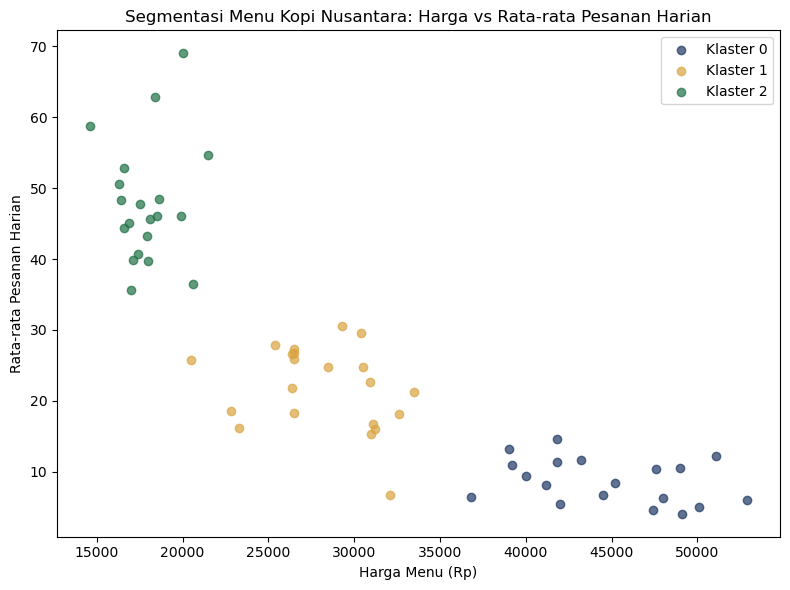

In [10]:
pdf_menu = pred_menu.select("harga", "rata_rata_pesanan_harian", "prediction").toPandas()

plt.figure(figsize=(8, 6))
warna_menu = ["#1F3864", "#D9A441", "#1E7145"]
for klaster in sorted(pdf_menu["prediction"].unique()):
    subset = pdf_menu[pdf_menu["prediction"] == klaster]
    plt.scatter(
        subset["harga"],
        subset["rata_rata_pesanan_harian"],
        label=f"Klaster {klaster}",
        color=warna_menu[klaster],
        alpha=0.7
    )

plt.title("Segmentasi Menu Kopi Nusantara: Harga vs Rata-rata Pesanan Harian")
plt.xlabel("Harga Menu (Rp)")
plt.ylabel("Rata-rata Pesanan Harian")
plt.legend()
plt.tight_layout()
plt.show()

Berdasarkan hasil segmentasi menu dengan KMeans, ide paket bundling promo yang disarankan adalah "Paket Hemat Harian & Coba Rasa", yakni menggabungkan satu menu dari klaster Menu Andalan Populer (harga terjangkau dan pesanan harian tinggi) dengan satu menu dari klaster Menu Premium Kurang Laris atau Menu Pelengkap Reguler dengan potongan harga paket terbatas. Secara bisnis, menu yang sudah sangat populer berperan sebagai penarik utama (traffic driver) agar paket lebih mudah dilirik pelanggan, sementara menu dengan harga lebih tinggi atau pesanan harian lebih rendah mendapatkan eksposur dan peningkatan volume penjualan tanpa menurunkan harga satuan secara berlebihan, sekaligus membantu tim dapur merencanakan stok bahan baku secara lebih terukur.

In [11]:
spark.stop()
print("SparkSession ditutup.")

SparkSession ditutup.
